# 05 – EDA bổ sung theo rubric

Notebook lưu hình vào `figures/`, bảng vào `report/`. Nhận xét được bổ sung từ kết quả hiện có, cần cập nhật nếu dữ liệu thay đổi.


In [1]:
import sys, os
sys.path.insert(0, "..")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew, spearmanr
from src.data import load_sets, load_category, P
from src.features import feature_frame, FEATURE_NAMES

FIG, REP = "../figures", "../report"
os.makedirs(FIG, exist_ok=True)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

shp = pd.read_csv(P / "shopee_clean_all.csv")
shp["product"] = shp["product"].str.normalize("NFC")
shp = shp.merge(load_category(), on="product", how="left")
sets = load_sets()
print(len(shp), "review Shopee;", shp.category.isna().sum(), "dòng thiếu ngành hàng")

2548 review Shopee; 0 dòng thiếu ngành hàng


## 1. Từ điển dữ liệu (P3.1)

Cột "Ý nghĩa kinh doanh" là phần rubric muốn thấy: biến này giúp người ra quyết định điều gì.

In [2]:
dd = pd.DataFrame([
    ("Shopee", "id", "chuỗi", "Mã review do nhóm tạo (shp_XXXX)", "Truy vết review, ẩn danh người mua"),
    ("Shopee", "product", "chuỗi", "Tên sản phẩm (32 sản phẩm)", "Đơn vị để so sánh chất lượng giữa các mặt hàng"),
    ("Shopee", "category", "chuỗi", "Ngành hàng, nhóm tự gán (9 ngành)", "So sánh mức hài lòng giữa ngành hàng"),
    ("Shopee", "rating", "số nguyên 1–5", "Số sao người mua chấm", "Mức hài lòng tổng quát; là nhãn yếu"),
    ("Shopee", "text", "chuỗi", "Nội dung review gốc", "Nguồn insight về lý do hài lòng/không hài lòng"),
    ("Shopee", "text_clean", "chuỗi", "Review đã bỏ nhãn mục template, gộp khoảng trắng", "Đầu vào cho phân tích"),
    ("Shopee", "weak_label", "pos/neu/neg", "Nhãn suy từ sao: 1–2 neg, 3 neu, 4–5 pos", "Nhãn huấn luyện rẻ nhưng nhiễu"),
    ("ViSD4SA", "text", "chuỗi", "Review điện thoại", "Dữ liệu huấn luyện có nhãn chuẩn"),
    ("ViSD4SA", "labels", "danh sách [start, end, KHÍA_CẠNH#CẢM_XÚC]", "Nhãn theo cụm từ, 10 khía cạnh", "Cho biết khách khen/chê phần nào"),
    ("ViSD4SA", "label", "pos/neu/neg", "Nhãn cả câu, nhóm tự gộp từ nhãn cụm", "Mục tiêu phân loại"),
    ("ViSD4SA", "chat_luong, gia_ca, dich_vu", "pos/neu/neg/trống", "Cảm xúc theo 3 nhóm khía cạnh", "Huấn luyện ABSA"),
    ("Aug", "text", "chuỗi", "Review không dấu", "Mô phỏng người dùng gõ không dấu"),
    ("Aug", "rating, label", "1–5, positive/negative", "Sao và nhãn 2 lớp", "Chỉ dùng để huấn luyện"),
    ("Tập vàng", "sentiment", "pos/neu/neg", "Nhãn tay theo labeling/guideline.md", "Thước đo chất lượng mô hình thật"),
    ("Tập vàng", "giao_hang … dich_vu", "pos/neu/neg/none", "Nhãn tay theo 4 khía cạnh", "Đánh giá ABSA"),
], columns=["Nguồn", "Biến", "Kiểu", "Mô tả", "Ý nghĩa kinh doanh"])
dd.to_csv(f"{REP}/data_dictionary.csv", index=False, encoding="utf-8-sig")
dd

,Nguồn,Biến,Kiểu,Mô tả,Ý nghĩa kinh doanh
0,Shopee,id,chuỗi,Mã review do nhóm tạo (shp_XXXX),"Truy vết review, ẩn danh người mua"
1,Shopee,product,chuỗi,Tên sản phẩm (32 sản phẩm),Đơn vị để so sánh chất lượng giữa các mặt hàng
2,Shopee,category,chuỗi,"Ngành hàng, nhóm tự gán (9 ngành)",So sánh mức hài lòng giữa ngành hàng
3,Shopee,rating,số nguyên 1–5,Số sao người mua chấm,Mức hài lòng tổng quát; là nhãn yếu
4,Shopee,text,chuỗi,Nội dung review gốc,Nguồn insight về lý do hài lòng/không hài lòng
5,Shopee,text_clean,chuỗi,"Review đã bỏ nhãn mục template, gộp khoảng trắng",Đầu vào cho phân tích
6,Shopee,weak_label,pos/neu/neg,"Nhãn suy từ sao: 1–2 neg, 3 neu, 4–5 pos",Nhãn huấn luyện rẻ nhưng nhiễu
7,ViSD4SA,text,chuỗi,Review điện thoại,Dữ liệu huấn luyện có nhãn chuẩn
8,ViSD4SA,labels,"danh sách [start, end, KHÍA_CẠNH#CẢM_XÚC]","Nhãn theo cụm từ, 10 khía cạnh",Cho biết khách khen/chê phần nào
9,ViSD4SA,label,pos/neu/neg,"Nhãn cả câu, nhóm tự gộp từ nhãn cụm",Mục tiêu phân loại


In [3]:
summary = pd.DataFrame({
    "Nguồn": ["A: ViSD4SA (train/dev/test)", "B: Shopee (sau làm sạch)", "Aug: không dấu (đã lọc)"],
    "Số quan sát": [sum(len(sets[k]) for k in ["A", "A_dev", "A_test"]), len(shp), len(sets["Aug"])],
    "Miền": ["Điện thoại", "32 sản phẩm, 9 ngành hàng", "Mỹ phẩm, đa ngành"],
    "Nhãn": ["Cụm từ → câu", "Sao (yếu) + 300 câu tay", "2 lớp"],
})
summary.to_csv(f"{REP}/data_sources.csv", index=False, encoding="utf-8-sig")
summary

,Nguồn,Số quan sát,Miền,Nhãn
0,A: ViSD4SA (train/dev/test),10510,Điện thoại,Cụm từ → câu
1,B: Shopee (sau làm sạch),2548,"32 sản phẩm, 9 ngành hàng",Sao (yếu) + 300 câu tay
2,Aug: không dấu (đã lọc),1205,"Mỹ phẩm, đa ngành",2 lớp


## 2. Phân phối biến mục tiêu và độ lệch

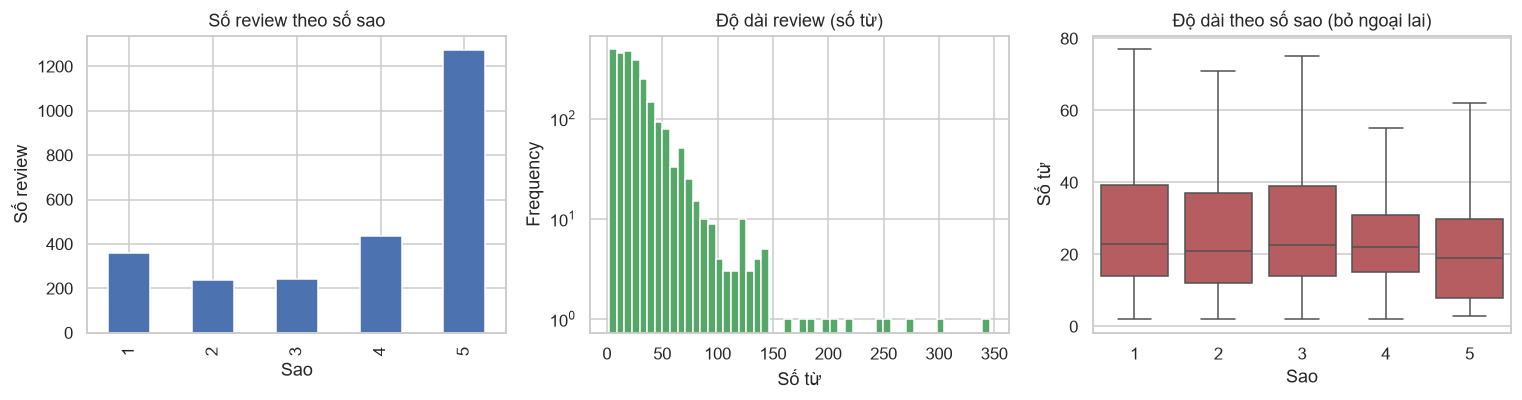

Skewness số sao: -0.86  (âm = dồn về phía 5 sao)
Skewness độ dài: 4.12; sau log1p: -0.03
Trung vị số từ theo sao: {1: 23.0, 2: 21.0, 3: 22.5, 4: 22.0, 5: 19.0}


In [4]:
shp["n_words"] = shp.text_clean.str.split().str.len()
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
shp.rating.value_counts().sort_index().plot.bar(ax=ax[0], color="#4C72B0")
ax[0].set(title="Số review theo số sao", xlabel="Sao", ylabel="Số review")
shp.n_words.plot.hist(bins=50, ax=ax[1], color="#55A868")
ax[1].set(title="Độ dài review (số từ)", xlabel="Số từ", yscale="log")
sns.boxplot(data=shp, x="rating", y="n_words", ax=ax[2], showfliers=False, color="#C44E52")
ax[2].set(title="Độ dài theo số sao (bỏ ngoại lai)", xlabel="Sao", ylabel="Số từ")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_target_length.png", bbox_inches="tight"); plt.show()

print(f"Skewness số sao: {skew(shp.rating):.2f}  (âm = dồn về phía 5 sao)")
print(f"Skewness độ dài: {skew(shp.n_words):.2f}; sau log1p: {skew(np.log1p(shp.n_words)):.2f}")
print("Trung vị số từ theo sao:", shp.groupby("rating").n_words.median().to_dict())

**Nhận xét.** Phân phối sao lệch trái với skewness −0,86, tập trung về phía nhiều sao. Độ dài review lệch phải mạnh (4,12); sau log1p, skewness còn −0,03. Trung vị độ dài ở 1 sao là 23 từ, trong khi 5 sao là 19 từ (notebook 05). Điểm sao cao không có nghĩa không có phản ánh cần xử lý. Review dài có thể chứa nhiều thông tin nên không loại chỉ vì dài; log độ dài giúp giảm ảnh hưởng của văn bản quá dài khi tạo đặc trưng, không phải quy tắc xác định cảm xúc.

## 3. Cảm xúc theo ngành hàng

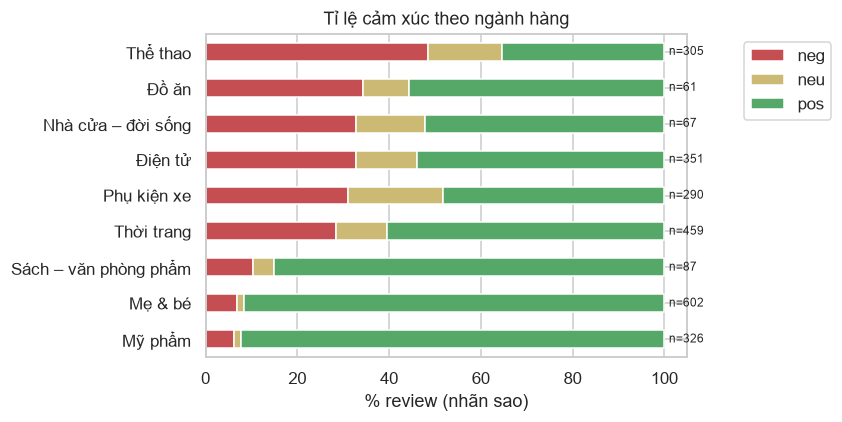

weak_label,neg,neu,pos
category,,,
Mỹ phẩm,6.1,1.5,92.3
Mẹ & bé,6.8,1.7,91.5
Sách – văn phòng phẩm,10.3,4.6,85.1
Thời trang,28.5,11.1,60.3
Phụ kiện xe,31.0,20.7,48.3
Điện tử,32.8,13.4,53.8
Nhà cửa – đời sống,32.8,14.9,52.2
Đồ ăn,34.4,9.8,55.7
Thể thao,48.5,16.1,35.4


In [5]:
ct = pd.crosstab(shp.category, shp.weak_label, normalize="index")[["neg", "neu", "pos"]] * 100
ct = ct.sort_values("neg")
ax = ct.plot.barh(stacked=True, figsize=(8, 4), color=["#C44E52", "#CCB974", "#55A868"])
ax.set(xlabel="% review (nhãn sao)", ylabel="", title="Tỉ lệ cảm xúc theo ngành hàng")
ax.legend(loc="upper left", bbox_to_anchor=(1.1, 1))
for i, (n, v) in enumerate(zip(shp.category.value_counts()[ct.index], ct.neg)):
    ax.text(101, i, f"n={n}", va="center", fontsize=8)
plt.tight_layout(); plt.savefig(f"{FIG}/eda_category_sentiment.png", bbox_inches="tight"); plt.show()
ct.round(1)

**Nhận xét.** Thể thao có tỷ lệ nhãn sao tiêu cực cao nhất trong mẫu (48,5%), tiếp đến Đồ ăn (34,4%); Mỹ phẩm và Mẹ & bé thấp hơn (6,1% và 6,8%). Đây là nhãn suy từ sao, khác cảm xúc do người hoặc mô hình xác định từ văn bản. Chênh lệch gợi ý ưu tiên đọc lại nhóm có nhiều phản ánh, nhưng không đủ để kết luận chất lượng cả ngành: cơ cấu sản phẩm và cỡ mẫu không đồng đều, một số ngành chỉ có một sản phẩm.

## 4. Đặc trưng mới (feature engineering) và tương quan

6 đặc trưng trong `src/features.py`, tính trên **văn bản gốc**:
- `n_words`: độ dài;
- `n_negation`: số từ phủ định;
- `n_contrast`: số từ đối lập ("nhưng", "mà", "tuy");
- `n_exclaim`: số dấu "!";
- `upper_ratio`: tỉ lệ chữ HOA;
- `accent_ratio`: tỉ lệ chữ có dấu.

Dùng **Spearman** vì số sao là biến thứ bậc và các đặc trưng đếm bị lệch.

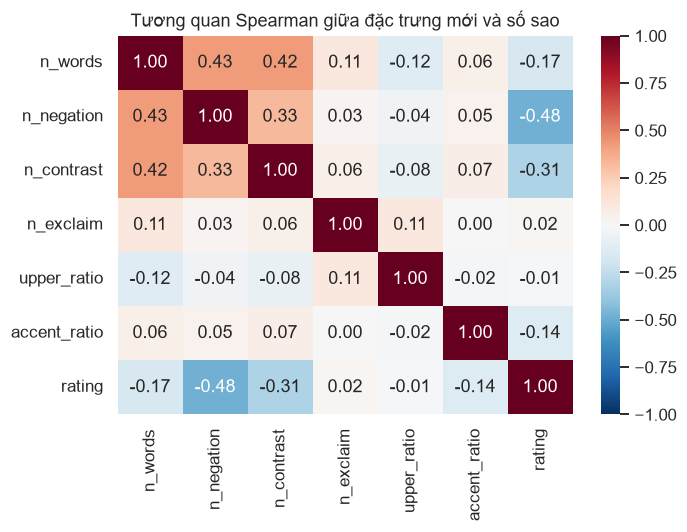

,feature,spearman_rating,p_value
1,n_negation,-0.478,1.809276e-145
2,n_contrast,-0.312,1.552297e-58
0,n_words,-0.166,3.505116e-17
5,accent_ratio,-0.136,6.122750e-12
4,upper_ratio,-0.009,6.354122e-01
3,n_exclaim,0.020,3.086254e-01


In [6]:
F = feature_frame(shp.text_clean)
F["rating"] = shp.rating.values
corr = F.corr(method="spearman")
plt.figure(figsize=(6.5, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1)
plt.title("Tương quan Spearman giữa đặc trưng mới và số sao")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_feature_corr.png", bbox_inches="tight"); plt.show()

rows = []
for c in FEATURE_NAMES:
    r, p = spearmanr(F[c], F.rating)
    rows.append({"feature": c, "spearman_rating": round(r, 3), "p_value": p})
feat_corr = pd.DataFrame(rows).sort_values("spearman_rating")
feat_corr.to_csv(f"{REP}/feature_corr.csv", index=False)
feat_corr

In [7]:
F["weak_label"] = shp.weak_label.values
mean_by_label = F.groupby("weak_label")[FEATURE_NAMES].mean().loc[["neg", "neu", "pos"]].round(3)
mean_by_label.to_csv(f"{REP}/feature_mean_by_label.csv")
mean_by_label

,n_words,n_negation,n_contrast,n_exclaim,upper_ratio,accent_ratio
weak_label,,,,,,
neg,31.608,1.544,0.677,0.102,0.031,0.279
neu,31.950,1.244,0.773,0.041,0.031,0.281
pos,23.050,0.387,0.240,0.059,0.028,0.262


**Nhận xét.** Số từ phủ định tương quan âm mạnh nhất với sao (Spearman −0,478), tiếp theo là từ đối lập như “nhưng” (−0,312). Độ dài tương quan âm yếu hơn (−0,166); tỷ lệ chữ hoa (−0,009) và dấu chấm than (0,020) gần như không có quan hệ đơn điệu. Kết quả ủng hộ giữ tín hiệu phủ định và cấu trúc khen–chê, nhưng tương quan không chứng minh nguyên nhân hay bảo đảm tăng điểm mô hình. Đặc trưng chỉ tính từ văn bản; sao dùng đối chiếu EDA, không làm đầu vào dự đoán.

## 5. Từ được nhắc nhiều trong review tiêu cực và tích cực

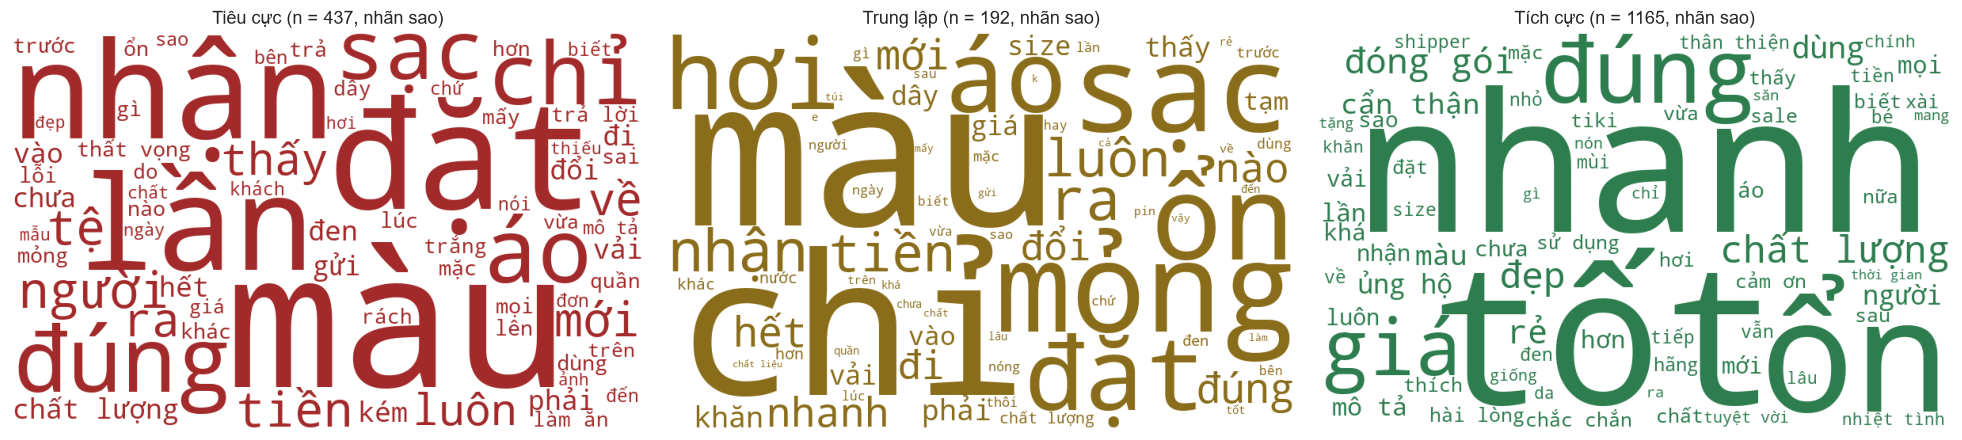

In [8]:
from wordcloud import WordCloud
from src.aspects import word_freq
tr = pd.read_csv(P / "shopee_train.csv")
fig, ax = plt.subplots(1, 3, figsize=(18, 5))
for a, lab, ten, mau in [(ax[0], "neg", "Tiêu cực", "#A32A2A"), (ax[1], "neu", "Trung lập", "#8A6D1B"), (ax[2], "pos", "Tích cực", "#2E7D4F")]:
    d = tr[tr.weak_label == lab]
    wc = WordCloud(width=800, height=500, background_color="white", max_words=70, prefer_horizontal=1.0,
                   color_func=lambda *args, m=mau, **kw: m, random_state=42).generate_from_frequencies(word_freq(d.text_prep))
    a.imshow(wc); a.axis("off"); a.set_title(f"{ten} (n = {len(d)}, nhãn sao)")
plt.tight_layout(); plt.savefig(f"{FIG}/eda_wordcloud.png", bbox_inches="tight", dpi=150); plt.show()
